In [1]:
# load my device log from the SD card (real readings, no labels)
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from data_quality import run_quality_checks
from kalman_filter import run_kalman_stage, KALMAN_SETTINGS
from entropy_weighting import make_indicators
from fuzzy_logic import run_fuzzy_stage, MIN_GRADING_LUX

raw = pd.read_csv("../data/device/log_003.csv")

# the device has no clock (RTC), so the time is "seconds since start" (uptime_s)
# the pipeline needs a timestamp and a device id, so we make them from uptime
start = pd.Timestamp("2026-10-21 00:00:00", tz="UTC")   # any start, only the gaps matter
raw["timestamp_utc"] = start + pd.to_timedelta(raw["uptime_s"], unit="s")
raw["device_id"] = "ESP32-DEV"

print("Readings:", len(raw), "| minutes:", round(raw["uptime_s"].max() / 60, 1))
print("Relay ON readings (panel cut):", (raw["relay_on"] == 1).sum())
print()
raw[["record_id", "uptime_s", "voltage_v", "current_ma", "irradiance_lux", "dust_lpo_pct", "relay_on"]].head()

Readings: 1000 | minutes: 33.3
Relay ON readings (panel cut): 215



,record_id,uptime_s,voltage_v,current_ma,irradiance_lux,dust_lpo_pct,relay_on
0,M1-DEV-003-0000001,2.0,0.096,0.8,300.3,NaN,0
1,M1-DEV-003-0000002,4.0,0.120,1.0,296.4,NaN,0
2,M1-DEV-003-0000003,6.0,0.672,5.6,299.1,NaN,0
3,M1-DEV-003-0000004,8.0,0.048,0.4,204.7,NaN,0
4,M1-DEV-003-0000005,10.0,0.024,0.2,200.5,NaN,0


In [2]:
# Stage 1: data quality on real device data

clean = run_quality_checks(raw)

print("Rows:", len(raw), "->", len(clean))
print("Sessions:", clean["session_id"].nunique())
print()
print(clean["quality_flag"].value_counts())
print()

# when the relay cuts the panel, the current must be 0 (an open circuit)
print("Median current, relay OFF:", clean.loc[clean["relay_on"] == 0, "current_ma"].median(), "mA")
print("Median current, relay ON :", clean.loc[clean["relay_on"] == 1, "current_ma"].median(), "mA")

Rows: 1000 -> 1000
Sessions: 1

quality_flag
OK                             949
SPIKE_VOLTAGE                   42
SPIKE_VOLTAGE|SPIKE_CURRENT      9
Name: count, dtype: int64

Median current, relay OFF: 0.9 mA
Median current, relay ON : 0.0 mA


sensor            noise before   noise after   removed
voltage_v               0.0437        0.0154       65%
current_ma              0.5192        0.1768       66%
panel_temp1_c           0.0256        0.0071       72%
ambient_temp_c          0.0215        0.0061       72%


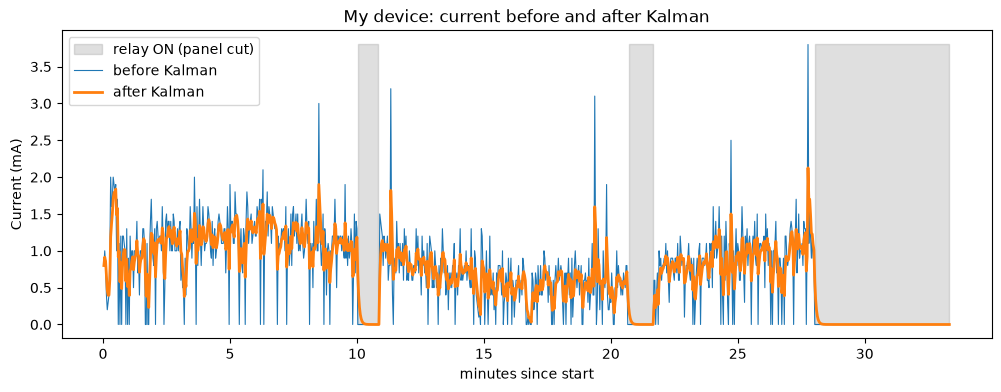

In [3]:
# Stage 2: Kalman filter on real sensor noise

filtered = run_kalman_stage(clean)

sensors = [c for c in KALMAN_SETTINGS if c in clean.columns]
print(f"{'sensor':<16}{'noise before':>14}{'noise after':>14}{'removed':>10}")
for col in sensors:
    before = clean.groupby("session_id")[col].diff().std()
    after = filtered.groupby("session_id")[col].diff().std()
    print(f"{col:<16}{before:>14.4f}{after:>14.4f}{1 - after / before:>10.0%}")

# plot the current: before and after Kalman, relay ON shown in grey
t = clean["uptime_s"] / 60
plt.figure(figsize=(12, 4))
plt.fill_between(t, 0, clean["current_ma"].max(), where=clean["relay_on"] == 1,
                 color="grey", alpha=0.25, label="relay ON (panel cut)")
plt.plot(t, clean["current_ma"], linewidth=0.8, label="before Kalman")
plt.plot(t, filtered["current_ma"], linewidth=2, label="after Kalman")
plt.title("My device: current before and after Kalman")
plt.xlabel("minutes since start")
plt.ylabel("Current (mA)")
plt.legend()
plt.show()

In [4]:
# Stage 3: compare with a healthy panel (physics model)

ind = make_indicators(filtered)

print("Median indicator (1 = like a healthy panel):")
print(ind.groupby(ind["relay_on"].map({0: "relay OFF", 1: "relay ON"}))
         [["current_ratio", "voltage_ratio", "power_ratio"]].median().round(2))

Median indicator (1 = like a healthy panel):
           current_ratio  voltage_ratio  power_ratio
relay_on                                            
relay OFF            1.0            1.0          1.0
relay ON             0.0            0.0          0.0


In [5]:
# Stage 4: fuzzy grading

graded = run_fuzzy_stage(filtered)

print("Light on my device: min", round(graded["irradiance_lux"].min()), "lux, max", round(graded["irradiance_lux"].max()), "lux")
print("Grading starts at", MIN_GRADING_LUX, "lux")
print()
print(graded["health_status"].value_counts())

Light on my device: min 150 lux, max 480 lux
Grading starts at 500.0 lux

health_status
NOT_GRADED    1000
Name: count, dtype: int64
